# Week 3 - NumPy Fundamentals

**Paññāsāstra University of Cambodia**
**Course:** Data Analysis and Visualization (3 credits)
**Chapter 3 - NumPy Fundamentals**

---

## Session topics (from the course outline)

- Arrays versus lists
- Array creation, indexing, slicing
- Mathematical operations with arrays

## Course learning outcomes addressed

| CLO | Statement |
|---|---|
| **CLO 2** | Identify suitable tools and techniques for analyzing different types of datasets |
| **CLO 3** | Apply Python libraries (NumPy, Pandas) to clean, manipulate, and process datasets |
| **CLO 5** | Perform exploratory data analysis (EDA) to summarize and interpret datasets |

## Reading

| Topic | Source |
|---|---|
| The ndarray, creation, dtypes, indexing | McKinney §4.1 |
| Pseudorandom number generation | McKinney §4.2 |
| Universal functions | McKinney §4.3 |
| Array-oriented programming, statistics, sorting | McKinney §4.4 |
| Linear algebra | McKinney §4.6 |
| Arrays, creation, arithmetic, indexing | Pfaffelhuber §6.1–6.4 |
| Vectorization and broadcasting | Pfaffelhuber §6.5 |
| Aggregation and the axis parameter | Pfaffelhuber §6.7 |

## Why NumPy comes before pandas

A pandas `DataFrame` column is a NumPy array underneath. Every arithmetic operation, every
comparison and every aggregation you will write in pandas is a NumPy operation wearing a
label. Learning the array first means that when pandas behaves unexpectedly in Week 5, you
recognise the behaviour rather than meeting it for the first time.

This session also introduces the two ideas that make array code different from the loops you
wrote in Week 2: **vectorisation** and **broadcasting**.

---

## Setup

All imports for this notebook are defined in the single cell below. Run it first. If any
import fails, return to Notebook 00 and check that the kernel in the top-right corner points
inside your `venv`.

In [1]:
# ---------------------------------------------------------------------------
# All imports for this notebook. Run this cell first.
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Reproducibility: every dataset in this notebook is generated from this seed,
# so your numbers will match the ones shown in the lecture exactly.
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Consistent, colour-blind-safe plotting defaults for the whole course.
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "font.size": 10,
})
sns.set_palette(PALETTE)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print("Environment ready.")
print(f"  numpy   {np.__version__}")
print(f"  pandas  {pd.__version__}")
print(f"  seaborn {sns.__version__}")
print(f"  seed    {RANDOM_SEED}")

Environment ready.
  numpy   2.5.3
  pandas  3.0.6
  seaborn 0.13.2
  seed    42


---

# Part 1 - Theory and concepts

## 1.1 What an `ndarray` is

A NumPy `ndarray` is a block of memory holding values of **one type**, laid out
**contiguously**, with a **fixed size**. A Python list is an array of pointers to objects
scattered across memory, each carrying its own type information.

| Property | Python `list` | NumPy `ndarray` |
|---|---|---|
| Element types | Mixed | One, fixed at creation |
| Memory layout | Pointers to scattered objects | One contiguous block |
| Size | Grows and shrinks | Fixed; "growing" builds a new array |
| Arithmetic | Element by element, in Python | Whole array, in compiled C |
| Per-element overhead | ~28 bytes for a small int | 8 bytes for `int64` |

Those differences produce the one that matters: arithmetic on an array runs in compiled code
over contiguous memory, while the same arithmetic on a list runs a Python loop over scattered
objects. The measured gap is typically one to two orders of magnitude, and Part 2 measures it
rather than asserting it.

## 1.2 Attributes of an array

Every array carries four facts about itself:

| Attribute | Meaning |
|---|---|
| `.shape` | A tuple giving the length along each axis, e.g. `(3, 4)` |
| `.ndim` | The number of axes; `len(shape)` |
| `.dtype` | The element type, e.g. `int64`, `float64`, `bool` |
| `.size` | The total number of elements; the product of `shape` |

## 1.3 Creating arrays

```python
np.array([1, 2, 3])            # from a sequence
np.zeros((3, 4))               # filled with 0.0
np.ones((2, 3))                # filled with 1.0
np.full((2, 2), 7)             # filled with a value
np.arange(0, 10, 2)            # like range(), but an array
np.linspace(0, 1, 5)           # n evenly spaced points, endpoints included
np.eye(3)                      # identity matrix
```

`arange` takes a **step**; `linspace` takes a **count**. `np.arange(0, 1, 0.1)` is the usual
source of trouble, because a floating-point step may or may not include the endpoint. Use
`linspace` whenever the number of points matters.

## 1.4 Data types

An array's `dtype` is fixed. Assigning a value of another type converts it silently:

```python
a = np.array([1, 2, 3])      # int64
a[0] = 3.7                   # stored as 3 -- truncated, no warning
```

Integer arrays also **overflow** rather than growing, unlike Python integers:

```python
np.array([127], dtype=np.int8) + 1     # -128
```

Neither behaviour raises. Both are demonstrated in Part 2, because a silently wrong number is
worse than an error.

## 1.5 Indexing and slicing

Indexing follows the same rules as lists, extended to several axes:

```python
a[2]          # one element of a 1-D array
a[1, 3]       # row 1, column 3 of a 2-D array
a[1]          # all of row 1
a[:, 3]       # all of column 3
a[0:2, 1:3]   # a rectangular block
```

**A slice of an array is a view, not a copy.** This is the most important difference from
lists, and it is the source of the most confusing bugs in array code.

```python
a = np.array([1, 2, 3, 4, 5])
b = a[1:4]        # a VIEW onto a's memory
b[0] = 99
print(a)          # [ 1 99  3  4  5]  -- a changed
```

A Python list slice copies. A NumPy slice does not: it is a window onto the same memory. This
is deliberate, because copying large arrays on every slice would be ruinous. When you need a
copy, ask for one with `.copy()`.

Two forms of indexing **do** copy:

| Form | Example | View or copy |
|---|---|---|
| Basic slicing | `a[1:4]`, `a[:, 0]` | **View** |
| Boolean indexing | `a[a > 3]` | Copy |
| Fancy indexing | `a[[0, 2, 4]]` | Copy |

## 1.6 Boolean indexing

A comparison on an array produces an array of booleans, which can then be used to select:

```python
scores > 80                  # array([False, True, ...])
scores[scores > 80]          # the values where the mask is True
scores[scores > 80] = 80     # assignment through a mask
```

Combine conditions with `&` (and), `|` (or) and `~` (not), **with parentheses**:

```python
scores[(scores > 60) & (scores < 80)]
```

The Python keywords `and`, `or` and `not` do not work element-wise and raise
`ValueError: The truth value of an array with more than one element is ambiguous`. That error
message means you used `and` where you needed `&`.

## 1.7 Vectorisation

Vectorisation means expressing a computation as whole-array operations rather than as a loop.

```python
# loop
result = []
for x in values:
    result.append(x * 2 + 1)

# vectorised
result = values * 2 + 1
```

The vectorised form is shorter, and it is faster because the loop runs in compiled C rather
than in the Python interpreter. Functions that operate element-wise on arrays are called
**universal functions**, or ufuncs: `np.sqrt`, `np.exp`, `np.log`, `np.maximum`, and the
arithmetic operators themselves.

## 1.8 Broadcasting

Broadcasting is the rule that lets arrays of different shapes combine. It is the conceptual
core of this session.

**The rule.** Compare the shapes from the **trailing** dimension backwards. Two dimensions
are compatible when they are equal, or when one of them is 1. A dimension of length 1 is
stretched to match. Missing leading dimensions are treated as 1.

```
   A      (3, 4)          A      (3, 4)          A      (3, 4)
   B         (4,)   ->    B      (3, 1)   ->     B      (2, 4)   ->  ERROR
   ------------           ------------           ------------
   result (3, 4)          result (3, 4)          3 and 2 do not match
```

Written arithmetically, for a matrix $A$ with $m$ rows and $n$ columns and a vector
$b$ of length $n$:

$$(A + b)_{ij} = A_{ij} + b_j$$

The vector is added to every row. If instead $b$ has shape $(m, 1)$, it is added to every
column:

$$(A + b)_{ij} = A_{ij} + b_i$$

Nothing is copied. NumPy iterates as though the stretched array existed, which is why
broadcasting is memory-efficient as well as concise.

The most common use in data work is centring or scaling a matrix by a per-column statistic:

$$Z_{ij} = \frac{A_{ij} - \bar{A}_j}{s_j}$$

which is one line once broadcasting is understood.

## 1.9 The `axis` parameter

Every aggregation takes an `axis` argument, and its meaning is the one thing in NumPy that
students reliably get backwards.

**`axis` names the dimension that disappears.**

For a 2-D array of shape `(rows, columns)`:

| Call | Collapses | Result shape | Plain English |
|---|---|---|---|
| `a.sum()` | everything | scalar | The grand total |
| `a.sum(axis=0)` | rows | `(columns,)` | One total **per column** |
| `a.sum(axis=1)` | columns | `(rows,)` | One total **per row** |

`axis=0` feels like it should mean "along rows" and give a result per row. It does not. It
means axis 0 — the row axis — is the one collapsed, leaving one value for each column. Read
it as "which axis am I removing".

`keepdims=True` retains the collapsed axis with length 1, which is what makes the result
broadcast back against the original:

```python
a - a.mean(axis=1, keepdims=True)     # subtract each row's mean from that row
```

Without `keepdims`, the shape `(rows,)` would align against the *columns* and either fail or,
worse, silently do the wrong thing on a square matrix.

---

In [2]:
##Create some arrays
arr1 = np.array([1, 2, 3])            # from a sequence
arr2d = np.array([[1, 2, 3], [4, 5, 6]])  # from a nested sequence
arr2 = np.zeros((3, 4))               # filled with 0.0
arr3 = np.ones((2, 3))                # filled with 1.0
arr4 = np.full((2, 2), 7)             # filled with a value
arr5 = np.arange(0, 10, 2)            # like range(), but an array
arr6 = np.linspace(0, 1, 5)           # n evenly spaced points, endpoints included
arr7 = np.eye(3)
arr2d.size #check size of the array
arr2d.shape #check shape of the array (rows, columns)
arr2d.ndim #check dimension of the array
# arr2d.dtype #check data type of the array
# arr2d.itemsize #check size of each element in the array
# arr2d.nbytes #check total size of the array in bytes

2

In [3]:
##3D array
# arr3d = np.array([[[1, 2, 3], [3, 4, 5]], [[5, 6, 7], [7, 8, 9]]]) #3D array
arr3d = np.array([[[1, 2, 3], [3, 4, 5], [5, 6, 7]], [[5, 6, 7], [7, 8, 9], [9, 10, 11]]]) #3D array
arr3d.shape, arr3d #check shape of the 3D array (depth, rows, columns)
# arr3d.ndim #check dimension of the 3D array
# arr3d.size #check size of the 3D array


((2, 3, 3),
 array([[[ 1,  2,  3],
         [ 3,  4,  5],
         [ 5,  6,  7]],
 
        [[ 5,  6,  7],
         [ 7,  8,  9],
         [ 9, 10, 11]]]))

In [4]:
#Create random arrays
arr8 = np.random.random((2, 3))             # uniform distribution over [0, 1)
arr9 = np.random.random((3, 2, 3))          # uniform distribution over [0, 1)
arr9

array([[[0.32369702, 0.44225337, 0.91681316],
        [0.74341003, 0.45962448, 0.21200918]],

       [[0.60726354, 0.24606424, 0.77081846],
        [0.05923384, 0.47836862, 0.06128201]],

       [[0.20243192, 0.86631841, 0.62290037],
        [0.9604705 , 0.75555421, 0.6494416 ]]])

In [5]:
zeroes = np.zeros((2, 3))  # array of zeros with shape (2, 3)
zeroes

array([[0., 0., 0.],
       [0., 0., 0.]])

In [6]:
fulls = np.full((2, 3), 7)  # array of sevens with shape (2, 3)
fulls

array([[7, 7, 7],
       [7, 7, 7]])

In [7]:
ones = np.ones((2, 3))  # array of ones with shape (2, 3)
ones

array([[1., 1., 1.],
       [1., 1., 1.]])

In [8]:
#indexing and slicing
arr10 = np.random.randint(0, 10, size=(3, 3, 4))  # random integers from 0 to 9
arr10


array([[[0, 1, 2, 6],
        [8, 4, 7, 7],
        [5, 4, 6, 3]],

       [[0, 8, 4, 8],
        [0, 8, 4, 9],
        [5, 7, 3, 1]],

       [[2, 1, 5, 7],
        [1, 5, 6, 0],
        [4, 5, 1, 6]]], dtype=int32)

In [9]:
#acessing
arr10[0]

array([[0, 1, 2, 6],
       [8, 4, 7, 7],
       [5, 4, 6, 3]], dtype=int32)

In [10]:
#slicing
arr10[0:2]

array([[[0, 1, 2, 6],
        [8, 4, 7, 7],
        [5, 4, 6, 3]],

       [[0, 8, 4, 8],
        [0, 8, 4, 9],
        [5, 7, 3, 1]]], dtype=int32)

In [11]:
arr10[-1] # access the last element along the first axis

array([[2, 1, 5, 7],
       [1, 5, 6, 0],
       [4, 5, 1, 6]], dtype=int32)

In [12]:
#update and delete elements
a1 = np.random.rand(2,3,2) # create a random 3D array
a2 = np.random.rand(2,3,2) # create another random 3D array

In [13]:
#add operations
np.add(a1, a2) # add two arrays


array([[[0.8059764 , 0.76326096],
        [0.84012873, 0.34153851],
        [0.53846704, 0.75657161]],

       [[0.72639713, 0.53511582],
        [0.74937606, 1.11098415],
        [1.20232199, 1.10526632]]])

In [14]:
#subtract operations
np.subtract(a1, a2) # subtract two arrays

array([[[-0.46740295, -0.1301762 ],
        [-0.30801292,  0.04248037],
        [-0.3162997 , -0.3513909 ]],

       [[ 0.62463772, -0.52005421],
        [ 0.49847023, -0.10335087],
        [ 0.5647457 , -0.54459104]]])

In [15]:
#divide operations
np.divide(a1, a2) # divide two arrays

array([[[ 0.26588578,  0.70859461],
        [ 0.46345832,  1.28409442],
        [ 0.25991575,  0.36569893]],

       [[13.27675665,  0.01427411],
        [ 4.97336501,  0.82978195],
        [ 2.77153923,  0.33983257]]])

In [16]:
#multiply operations
np.multiply(a1, a2) # multiply two arrays

array([[[0.10778311, 0.14140536],
        [0.15273608, 0.02871099],
        [0.04747531, 0.11223126]],

       [[0.03437013, 0.00397314],
        [0.07827298, 0.30590109],
        [0.28166011, 0.23125856]]])

In [17]:
sqrt_a1 = np.sqrt(a1) # square root of a1
abs_a1 = np.abs(a1) # absolute value of a1
power_a1 = np.power(a1, 2) # square of a1
log_a1 = np.log(a1) # natural logarithm of a1
mins = np.min(a1) # minimum value in a1
max_a1 = np.max(a1) # maximum value in a1


In [18]:
#update elements
a1[0, 0, 0] = 10 # update the first element
a1

array([[[1.00000000e+01, 3.16542376e-01],
        [2.66057902e-01, 1.92009442e-01],
        [1.11083669e-01, 2.02590353e-01]],

       [[6.75517424e-01, 7.53080474e-03],
        [6.23923145e-01, 5.03816639e-01],
        [8.83533844e-01, 2.80337636e-01]]])

In [19]:
#sort operations
sorted_a1 = np.sort(a1, axis=None) # sort the array in ascending order
sorted_a1

array([7.53080474e-03, 1.11083669e-01, 1.92009442e-01, 2.02590353e-01,
       2.66057902e-01, 2.80337636e-01, 3.16542376e-01, 5.03816639e-01,
       6.23923145e-01, 6.75517424e-01, 8.83533844e-01, 1.00000000e+01])

In [20]:
#reshape operations
reshaped_a1 = np.reshape(a1, (3, -1)) # reshape a1 to a 3x4 array
reshaped_a1

array([[1.00000000e+01, 3.16542376e-01, 2.66057902e-01, 1.92009442e-01],
       [1.11083669e-01, 2.02590353e-01, 6.75517424e-01, 7.53080474e-03],
       [6.23923145e-01, 5.03816639e-01, 8.83533844e-01, 2.80337636e-01]])

In [21]:
#appending and inserting elements
a1 = np.zeros((3, 2, 3))  # create a random 3D array
a2 = np.ones((3, 2, 3))  # create another random 3D array
a2

array([[[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]]])

In [22]:
#append operations
appended_a1 = np.append(a1, a2, axis=0) # append a2 to a1 along the first axis
appended_a1
#axis = 0 mean rows, axis = 1 mean columns, axis = 2 mean depth

array([[[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]]])

In [23]:
#insert operations
inserted_a1 = np.insert(a1, 2, a2, axis=0) # insert a2 into a1 at index 1 along the first axis
inserted_a1

array([[[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.]],

       [[0., 0., 0.],
        [0., 0., 0.]]])

In [24]:
#delete operations
deleted_a1 = np.delete(a1, 1, axis=0) # delete the second element along the first axis
deleted_a1

array([[[0., 0., 0.],
        [0., 0., 0.]],

       [[0., 0., 0.],
        [0., 0., 0.]]])

In [25]:
#boolean indexing
scores = np.array([45, 82, 67, 91, 55, 78, 88])
high_scores = scores[scores > 70]
high_scores

array([82, 91, 78, 88])

In [26]:
scores > 70

array([False,  True, False,  True, False,  True,  True])

In [27]:
scores[scores > 70] # update all scores greater than 70 to 100

array([82, 91, 78, 88])

In [28]:
scores[scores > 70] = 100 # update all scores greater than 70 to 100
scores

array([ 45, 100,  67, 100,  55, 100, 100])

In [29]:
#Vectorization
# loop
values = np.array([1, 2, 3, 4, 5])
result = []
for x in values:
    result.append(x * 2 + 1)

# vectorised
result = values * 2 + 1


In [30]:
result

array([ 3,  5,  7,  9, 11])

In [31]:
#Broadcasting
a = np.array([[1, 2, 3], [4, 5, 6]])
b = np.array([10, 20, 30])
c = a + b

In [32]:
c

array([[11, 22, 33],
       [14, 25, 36]])

In [33]:
#Broadcasting
a = np.ones((3, 3))  # create a 3x3 array of ones
b = np.array([[1], [2], [3]]) # Shape (3, 1)
c = a + b
a , b

(array([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]]),
 array([[1],
        [2],
        [3]]))

In [34]:
c

array([[2., 2., 2.],
       [3., 3., 3.],
       [4., 4., 4.]])

In [35]:
a = np.ones((3, 4))
b = np.ones((2, 4))
a , b

(array([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]]),
 array([[1., 1., 1., 1.],
        [1., 1., 1., 1.]]))

In [ ]:
# Axis parameters in NumPy functions allow you to specify the dimension along which an operation should be performed. In a 2D array, axis=0 refers to the rows (vertical direction), and axis=1 refers to the columns (horizontal direction).
# Create a sample 2-D array of shape (3, 4)
a = np.arange(12).reshape(3, 4)
print("Original Array a:\n", a)
print("Shape of a:", a.shape)
  
# 1. Plain sum: collapses everything into a single scalar
print("\n--- a.sum() ---")
print("Result:", a.sum())
print("Shape: ()")

# 2. axis=0: collapses the row dimension, leaving one total per column
print("\n--- a.sum(axis=0) [Collapses rows] ---")
print("Result:", a.sum(axis=0))
print("Shape:", a.sum(axis=0).shape)

# 3. axis=1: collapses the column dimension, leaving one total per row
print("\n--- a.sum(axis=1) [Collapses columns] ---")
print("Result:", a.sum(axis=1))
print("Shape:", a.sum(axis=1).shape)

Original Array a:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
Shape of a: (3, 4)

--- a.sum() ---
Result: 66
Shape: ()

--- a.sum(axis=0) [Collapses rows] ---
Result: [12 15 18 21]
Shape: (4,)

--- a.sum(axis=1) [Collapses columns] ---
Result: [ 6 22 38]
Shape: (3,)


In [37]:
# Without keepdims (shape becomes (3,))
mean_flat = a.mean(axis=1)
print("Mean without keepdims shape:", mean_flat.shape)

# With keepdims=True (shape remains (3, 1))
mean_kept = a.mean(axis=1, keepdims=True)
print("Mean with keepdims=True shape:", mean_kept.shape)

# Correct broadcasting: subtract each row's mean from that row's elements
centered_a = a - mean_kept
print("\nCentered Array (a - row_means):\n", centered_a)

Mean without keepdims shape: (3,)
Mean with keepdims=True shape: (3, 1)

Centered Array (a - row_means):
 [[-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]]


---

# Part 2 - Instructor code example

Complete and executable. It establishes, in order: that arrays differ from lists in a way you
can measure; that slices are views; how broadcasting composes; and what `axis` does.

## 2.1 Arrays and their attributes

In [38]:
def generate_score_matrix(n_students: int = 40, seed: int = RANDOM_SEED) -> np.ndarray:
    """Build a reproducible matrix of assessment scores.

    Parameters
    ----------
    n_students : int
        Number of rows.
    seed : int
        Seed for reproducibility.

    Returns
    -------
    numpy.ndarray
        Shape (n_students, 4): quiz, midterm, project, final. Values 0-100.
    """
    generator = np.random.default_rng(seed)

    # Each student has an underlying ability; each assessment has a difficulty.
    ability = generator.normal(0, 1, size=(n_students, 1))
    difficulty = np.array([[72.0, 64.0, 78.0, 68.0]])   # shape (1, 4)
    spread = np.array([[8.0, 11.0, 7.0, 12.0]])

    # Broadcasting builds the whole matrix in one expression:
    #   (n, 1) * (1, 4) -> (n, 4), then + (1, 4) -> (n, 4)
    scores = difficulty + ability * spread + generator.normal(0, 4, size=(n_students, 4))
    return np.clip(scores, 0, 100).round(1)


ASSESSMENTS = ["quiz", "midterm", "project", "final"]
scores = generate_score_matrix()

print("shape :", scores.shape)
print("ndim  :", scores.ndim)
print("dtype :", scores.dtype)
print("size  :", scores.size)

print("\nFirst five students:")
print(f"{'':<10}" + "".join(f"{name:>10}" for name in ASSESSMENTS))
for i in range(5):
    print(f"student {i:<3}" + "".join(f"{v:>10.1f}" for v in scores[i]))

shape : (40, 4)
ndim  : 2
dtype : float64
size  : 160

First five students:
                quiz   midterm   project     final
student 0        77.4      69.5      77.5      72.6
student 1        64.1      53.4      74.2      56.4
student 2        80.7      72.5      84.4      79.5
student 3        73.7      73.1      82.7      76.7
student 4        55.3      48.5      60.9      48.5


In [39]:
# Creation functions, and the arange / linspace distinction.
print("np.zeros((2, 3))     :\n", np.zeros((2, 3)))
print("\nnp.arange(0, 10, 2)  :", np.arange(0, 10, 2))
print("np.linspace(0, 1, 5) :", np.linspace(0, 1, 5))

# arange takes a STEP; linspace takes a COUNT. With floats the difference matters.
print("\nnp.arange(0, 1, 0.1) has", len(np.arange(0, 1, 0.1)), "elements")
print("np.linspace(0, 1, 11) has", len(np.linspace(0, 1, 11)), "elements")
print("\nThe endpoint is excluded by arange and included by linspace.")
print("When the number of points matters, use linspace.")

np.zeros((2, 3))     :
 [[0. 0. 0.]
 [0. 0. 0.]]

np.arange(0, 10, 2)  : [0 2 4 6 8]
np.linspace(0, 1, 5) : [0.   0.25 0.5  0.75 1.  ]

np.arange(0, 1, 0.1) has 10 elements
np.linspace(0, 1, 11) has 11 elements

The endpoint is excluded by arange and included by linspace.
When the number of points matters, use linspace.


## 2.2 Why arrays exist: a measured comparison

The claim in §1.1 is that array arithmetic is faster than a Python loop. Rather than assert
it, measure it.

In [40]:
def time_it(function, repeats: int = 3) -> float:
    """Run a zero-argument function a few times and return the best elapsed time.

    The best of several runs is used rather than the mean, because interference
    from other processes can only ever make a run slower.
    """
    best = float("inf")
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        best = min(best, time.perf_counter() - start)
    return best


N = 1_000_000
py_list = list(range(N))
np_array = np.arange(N)


def with_loop():
    """Square every element using a Python list comprehension."""
    return [x * x for x in py_list]


def with_numpy():
    """Square every element with a vectorised operation."""
    return np_array * np_array


loop_time = time_it(with_loop)
numpy_time = time_it(with_numpy)

print(f"Squaring {N:,} values")
print(f"  Python list : {loop_time * 1000:8.1f} ms")
print(f"  NumPy array : {numpy_time * 1000:8.1f} ms")
print(f"  NumPy is roughly {loop_time / numpy_time:.0f}x faster here")

print("\nThe exact ratio depends on the machine. The order of magnitude does not.")
print("The Python version runs a loop in the interpreter, allocating an object")
print("per element. The NumPy version runs one loop in compiled C over")
print("contiguous memory.")

Squaring 1,000,000 values
  Python list :     68.7 ms
  NumPy array :      2.9 ms
  NumPy is roughly 24x faster here

The exact ratio depends on the machine. The order of magnitude does not.
The Python version runs a loop in the interpreter, allocating an object
per element. The NumPy version runs one loop in compiled C over
contiguous memory.


In [41]:
# Memory is the other half of the story.
import sys

small_list = list(range(1000))
small_array = np.arange(1000)

list_bytes = sys.getsizeof(small_list) + sum(sys.getsizeof(x) for x in small_list)
array_bytes = small_array.nbytes

print(f"1,000 integers stored as a Python list : {list_bytes:>8,} bytes")
print(f"1,000 integers stored as a NumPy array : {array_bytes:>8,} bytes")
print(f"Ratio: {list_bytes / array_bytes:.1f}x")
print("\nThe list stores pointers to individual int objects, each carrying its")
print("own type and reference count. The array stores 1,000 raw 8-byte integers.")

1,000 integers stored as a Python list :   36,056 bytes
1,000 integers stored as a NumPy array :    8,000 bytes
Ratio: 4.5x

The list stores pointers to individual int objects, each carrying its
own type and reference count. The array stores 1,000 raw 8-byte integers.


## 2.3 Slicing, and the fact that a slice is a view

This is the behaviour most likely to produce a bug you cannot explain.

In [42]:
# A Python list slice COPIES.
py = [1, 2, 3, 4, 5]
py_slice = py[1:4]
py_slice[0] = 99
print("Python list after modifying its slice :", py)

# A NumPy slice is a VIEW onto the same memory.
arr = np.array([1, 2, 3, 4, 5])
arr_slice = arr[1:4]
arr_slice[0] = 99
print("NumPy array after modifying its slice :", arr)

print("\nThe array changed. The list did not.")
print("arr_slice is a window onto arr's memory, not a copy of it.")

# .base reveals the relationship.
print("\narr_slice.base is arr :", arr_slice.base is arr)

# To get a copy, ask for one.
arr = np.array([1, 2, 3, 4, 5])
safe = arr[1:4].copy()
safe[0] = 99
print("\nAfter .copy(), the original is unchanged:", arr)

Python list after modifying its slice : [1, 2, 3, 4, 5]
NumPy array after modifying its slice : [ 1 99  3  4  5]

The array changed. The list did not.
arr_slice is a window onto arr's memory, not a copy of it.

arr_slice.base is arr : True

After .copy(), the original is unchanged: [1 2 3 4 5]


In [43]:
# Which indexing forms copy, and which do not.
a = np.arange(10)

basic = a[2:5]          # slice          -> view
boolean = a[a > 5]      # boolean mask   -> copy
fancy = a[[1, 3, 5]]    # integer list   -> copy

print(f"{'form':<22}{'expression':<16}{'is a view?'}")
print("-" * 50)
print(f"{'basic slicing':<22}{'a[2:5]':<16}{basic.base is not None}")
print(f"{'boolean indexing':<22}{'a[a > 5]':<16}{boolean.base is not None}")
print(f"{'fancy indexing':<22}{'a[[1, 3, 5]]':<16}{fancy.base is not None}")

print("\nOnly basic slicing produces a view. Boolean and fancy indexing")
print("cannot, because the selected elements are not contiguous in memory.")

form                  expression      is a view?
--------------------------------------------------
basic slicing         a[2:5]          True
boolean indexing      a[a > 5]        False
fancy indexing        a[[1, 3, 5]]    False

Only basic slicing produces a view. Boolean and fancy indexing
cannot, because the selected elements are not contiguous in memory.


In [44]:
# 2-D indexing on the score matrix.
print("scores[0]        -> row 0, all assessments :", scores[0])
print("scores[0, 1]     -> student 0, midterm     :", scores[0, 1])
print("scores[:, 1][:6] -> midterm, all students  :", scores[:, 1][:6])
print("scores[0:3, 1:3] -> a rectangular block    :\n", scores[0:3, 1:3])

# The comma matters. scores[0][1] works but builds an intermediate row first.
print("\nscores[0, 1] and scores[0][1] give the same value:",
      scores[0, 1] == scores[0][1])
print("Prefer the comma form: it indexes once instead of twice.")

scores[0]        -> row 0, all assessments : [77.4 69.5 77.5 72.6]
scores[0, 1]     -> student 0, midterm     : 69.5
scores[:, 1][:6] -> midterm, all students  : [69.5 53.4 72.5 73.1 48.5 48.3]
scores[0:3, 1:3] -> a rectangular block    :
 [[69.5 77.5]
 [53.4 74.2]
 [72.5 84.4]]

scores[0, 1] and scores[0][1] give the same value: True
Prefer the comma form: it indexes once instead of twice.


## 2.4 Boolean indexing

Selecting by condition is how filtering is expressed in array code, and it is the direct
ancestor of `df[df["score"] > 80]` in pandas.

In [45]:
final_scores = scores[:, 3]

mask = final_scores >= 70
print("The mask is an array of booleans, one per student:")
print(mask[:12], "...")

print(f"\nStudents scoring 70 or more in the final: {mask.sum()} of {mask.size}")
print("mask.sum() works because True is 1 and False is 0.")

print("\nThe scores themselves:")
print(np.sort(final_scores[mask])[::-1][:10].round(1))

# Combine conditions with & | ~ and PARENTHESES.
middle = final_scores[(final_scores >= 60) & (final_scores < 70)]
print(f"\nBetween 60 and 70: {middle.size} students")

# The Python keyword 'and' does not work element-wise.
try:
    _ = final_scores[(final_scores >= 60) and (final_scores < 70)]
except ValueError as exc:
    print(f"\nUsing 'and' instead of '&' raises:\n  ValueError: {exc}")
    print("\nThat message always means: use & | ~ with parentheses.")

The mask is an array of booleans, one per student:
[ True False  True  True False False False False  True False  True  True] ...

Students scoring 70 or more in the final: 19 of 40
mask.sum() works because True is 1 and False is 0.

The scores themselves:
[90.4 86.  80.  79.5 77.4 77.2 77.  76.7 76.5 76.4]

Between 60 and 70: 11 students

Using 'and' instead of '&' raises:
  ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

That message always means: use & | ~ with parentheses.


In [46]:
# np.where: a vectorised if/else that returns an array.
grades = np.where(final_scores >= 70, "pass", "resit")
print("First 12 outcomes:", grades[:12])
print("Passes:", (grades == "pass").sum(), " Resits:", (grades == "resit").sum())

# Nested, for a banded grade. Readable up to about three levels.
bands = np.where(final_scores >= 80, "A",
         np.where(final_scores >= 70, "B",
          np.where(final_scores >= 60, "C", "D")))

unique, counts = np.unique(bands, return_counts=True)
print("\nGrade distribution:")
for band, count in zip(unique, counts):
    print(f"  {band}: {count:>3}  {'#' * count}")

First 12 outcomes: ['pass' 'resit' 'pass' 'pass' 'resit' 'resit' 'resit' 'resit' 'pass'
 'resit' 'pass' 'pass']
Passes: 19  Resits: 21

Grade distribution:
  A:   3  ###
  B:  16  ################
  C:  11  ###########
  D:  10  ##########


## 2.5 Broadcasting

The rule from §1.8, applied. Watch the shapes at every step.

In [47]:
matrix = np.arange(12).reshape(3, 4)
print("matrix, shape", matrix.shape, ":\n", matrix)

# Case 1: scalar. Stretched to every element.
print("\nmatrix + 100          ->", (matrix + 100).shape)
print(matrix + 100)

# Case 2: a row vector of shape (4,). Added to every ROW.
row = np.array([0, 10, 20, 30])
print(f"\nmatrix + row  {matrix.shape} + {row.shape} ->", (matrix + row).shape)
print(matrix + row)

# Case 3: a column vector of shape (3, 1). Added to every COLUMN.
column = np.array([[0], [100], [200]])
print(f"\nmatrix + column  {matrix.shape} + {column.shape} ->", (matrix + column).shape)
print(matrix + column)

matrix, shape (3, 4) :
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

matrix + 100          -> (3, 4)
[[100 101 102 103]
 [104 105 106 107]
 [108 109 110 111]]

matrix + row  (3, 4) + (4,) -> (3, 4)
[[ 0 11 22 33]
 [ 4 15 26 37]
 [ 8 19 30 41]]

matrix + column  (3, 4) + (3, 1) -> (3, 4)
[[  0   1   2   3]
 [104 105 106 107]
 [208 209 210 211]]


In [48]:
# Case 4: incompatible shapes raise, and the message names the shapes.
bad = np.array([1, 2, 3])          # shape (3,) against a trailing dimension of 4
try:
    matrix + bad
except ValueError as exc:
    print("matrix + bad raises:")
    print(f"  ValueError: {exc}")

print("\nWork the rule from the right:")
print("  matrix  (3, 4)")
print("  bad        (3,)")
print("           ^^^^ 4 and 3 are not equal, and neither is 1 -> error")

# The fix is to say which axis the vector belongs to.
print("\nReshaped to (3, 1), it aligns against the rows instead:")
print("  matrix  (3, 4)")
print("  bad     (3, 1)  ->  stretched to (3, 4)")
print(matrix + bad.reshape(3, 1))

matrix + bad raises:
  ValueError: operands could not be broadcast together with shapes (3,4) (3,) 

Work the rule from the right:
  matrix  (3, 4)
  bad        (3,)
           ^^^^ 4 and 3 are not equal, and neither is 1 -> error

Reshaped to (3, 1), it aligns against the rows instead:
  matrix  (3, 4)
  bad     (3, 1)  ->  stretched to (3, 4)
[[ 1  2  3  4]
 [ 6  7  8  9]
 [11 12 13 14]]


In [49]:
# The most common real use: standardise each column of the score matrix.
column_means = scores.mean(axis=0)          # shape (4,)
column_stds = scores.std(axis=0)            # shape (4,)

print(f"scores       {scores.shape}")
print(f"column_means {column_means.shape}   {column_means.round(2)}")
print(f"column_stds  {column_stds.shape}   {column_stds.round(2)}")

# (n, 4) - (4,) -> the vector aligns against the columns. One line.
z_scores = (scores - column_means) / column_stds

print(f"\nz_scores     {z_scores.shape}")
print("\nEach column now has mean 0 and standard deviation 1:")
print("  means:", z_scores.mean(axis=0).round(10))
print("  stds :", z_scores.std(axis=0).round(10))

print("\nWithout broadcasting this would be a nested loop over students and")
print("assessments. With it, it is one expression.")

scores       (40, 4)
column_means (4,)   [71.93 64.55 77.99 68.18]
column_stds  (4,)   [7.33 8.52 6.74 9.4 ]

z_scores     (40, 4)

Each column now has mean 0 and standard deviation 1:
  means: [-0. -0. -0.  0.]
  stds : [1. 1. 1. 1.]

Without broadcasting this would be a nested loop over students and
assessments. With it, it is one expression.


## 2.6 The `axis` parameter

`axis` names the dimension that disappears. This is worth proving rather than asserting,
because the intuition points the other way.

In [50]:
small = np.arange(12).reshape(3, 4)
print("small, shape (3, 4):\n", small)

print(f"\n{'call':<28}{'result shape':<16}{'meaning'}")
print("-" * 72)
print(f"{'small.sum()':<28}{'()':<16}grand total")
print(f"{'small.sum(axis=0)':<28}{str(small.sum(axis=0).shape):<16}one total per COLUMN")
print(f"{'small.sum(axis=1)':<28}{str(small.sum(axis=1).shape):<16}one total per ROW")

print("\nsmall.sum()      =", small.sum())
print("small.sum(axis=0) =", small.sum(axis=0), " <- 4 values, one per column")
print("small.sum(axis=1) =", small.sum(axis=1), " <- 3 values, one per row")

print("\nThe array has shape (3, 4).")
print("  axis=0 removes the 3 -> leaves (4,)")
print("  axis=1 removes the 4 -> leaves (3,)")
print("\nRead 'axis' as 'the axis I am collapsing', not 'the direction I move in'.")

small, shape (3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

call                        result shape    meaning
------------------------------------------------------------------------
small.sum()                 ()              grand total
small.sum(axis=0)           (4,)            one total per COLUMN
small.sum(axis=1)           (3,)            one total per ROW

small.sum()      = 66
small.sum(axis=0) = [12 15 18 21]  <- 4 values, one per column
small.sum(axis=1) = [ 6 22 38]  <- 3 values, one per row

The array has shape (3, 4).
  axis=0 removes the 3 -> leaves (4,)
  axis=1 removes the 4 -> leaves (3,)

Read 'axis' as 'the axis I am collapsing', not 'the direction I move in'.


In [51]:
# Applied to the real matrix: per-assessment and per-student views of the same data.
per_assessment = scores.mean(axis=0)
per_student = scores.mean(axis=1)

print("Mean by assessment (axis=0 collapses the students):")
for name, value in zip(ASSESSMENTS, per_assessment):
    print(f"  {name:<10}{value:>7.2f}")

print(f"\nMean by student (axis=1 collapses the assessments): {per_student.shape}")
print("  first five:", per_student[:5].round(2))
print(f"  best student: #{per_student.argmax()} with {per_student.max():.2f}")

# keepdims keeps the collapsed axis at length 1, so the result broadcasts back.
print(f"\nWithout keepdims: {scores.mean(axis=1).shape}")
print(f"With keepdims   : {scores.mean(axis=1, keepdims=True).shape}")

# Centre each STUDENT on their own average. This needs keepdims.
centred = scores - scores.mean(axis=1, keepdims=True)
print(f"\nCentred per student, shape {centred.shape}")
print("Each row now sums to zero:", np.allclose(centred.sum(axis=1), 0))

Mean by assessment (axis=0 collapses the students):
  quiz        71.93
  midterm     64.55
  project     77.99
  final       68.18

Mean by student (axis=1 collapses the assessments): (40,)
  first five: [74.25 62.02 79.28 76.55 53.3 ]
  best student: #30 with 90.10

Without keepdims: (40,)
With keepdims   : (40, 1)

Centred per student, shape (40, 4)
Each row now sums to zero: True


In [52]:
# The silent-failure case, and why keepdims is not optional.
square = np.arange(16).reshape(4, 4)

right = square - square.mean(axis=1, keepdims=True)   # (4,4) - (4,1) -> per row
wrong = square - square.mean(axis=1)                  # (4,4) - (4,)  -> per COLUMN

print("On a SQUARE matrix both forms run without error:")
print("\n  with keepdims (correct, rows centred) - row sums:", right.sum(axis=1))
print("  without keepdims (wrong)              - row sums:", wrong.sum(axis=1).round(2))

print("\nThe second subtracted the row means from the COLUMNS, because a shape")
print("(4,) vector aligns against the trailing axis. No error was raised.")
print("On a non-square matrix the same mistake raises ValueError instead,")
print("which is the friendlier outcome.")

On a SQUARE matrix both forms run without error:

  with keepdims (correct, rows centred) - row sums: [0. 0. 0. 0.]
  without keepdims (wrong)              - row sums: [-24.  -8.   8.  24.]

The second subtracted the row means from the COLUMNS, because a shape
(4,) vector aligns against the trailing axis. No error was raised.
On a non-square matrix the same mistake raises ValueError instead,
which is the friendlier outcome.


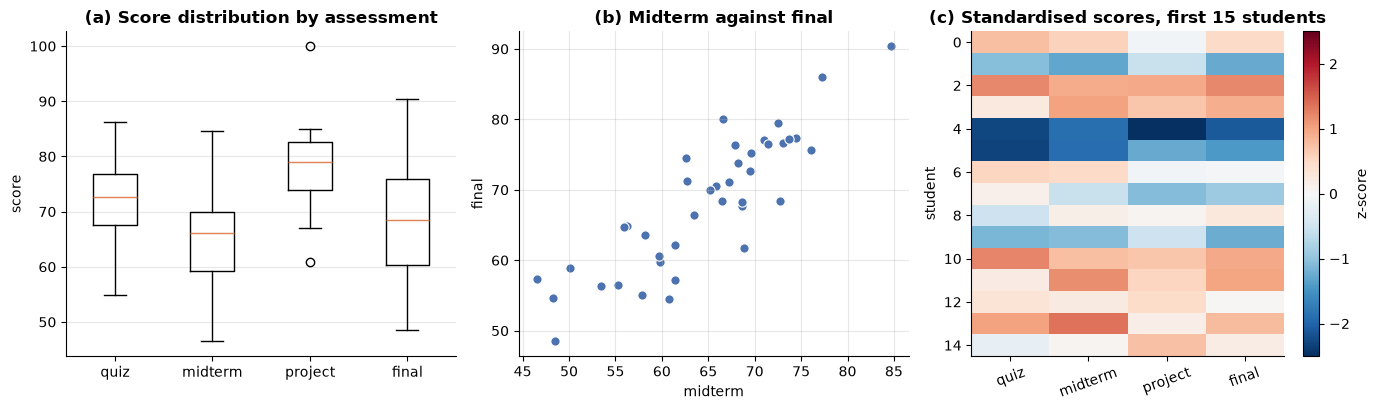

Correlation between midterm and final: r = 0.864


In [53]:
# A first look at the score data.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# Set the tick labels afterwards rather than passing them to boxplot: the
# keyword was renamed in matplotlib 3.9, so this form works on every version.
axes[0].boxplot([scores[:, i] for i in range(4)])
axes[0].set_xticks(range(1, len(ASSESSMENTS) + 1), ASSESSMENTS)
axes[0].set_title("(a) Score distribution by assessment")
axes[0].set_ylabel("score")
axes[0].grid(axis="x", alpha=0)

axes[1].scatter(scores[:, 1], scores[:, 3], s=45, color=PALETTE[0],
                edgecolor="white", linewidth=0.8)
axes[1].set_title("(b) Midterm against final")
axes[1].set_xlabel("midterm")
axes[1].set_ylabel("final")

image = axes[2].imshow(z_scores[:15], aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
axes[2].set_title("(c) Standardised scores, first 15 students")
axes[2].set_xticks(range(4), ASSESSMENTS, rotation=20)
axes[2].set_ylabel("student")
axes[2].grid(False)
fig.colorbar(image, ax=axes[2], label="z-score")

plt.tight_layout()
plt.show()

correlation = np.corrcoef(scores[:, 1], scores[:, 3])[0, 1]
print(f"Correlation between midterm and final: r = {correlation:.3f}")

---

# Part 3 - Guided workshop (in class)

Four tasks. Each has a verification cell.

### Task 1 - Create and reshape

**Problem.** Build `grid`: the integers from 1 to 24 inclusive, arranged as a 4-row by
6-column array.

**Hints**

- `np.arange(start, stop)` excludes `stop`, so you need `25`.
- `.reshape(rows, columns)` changes the shape without changing the data.

**Expected output.** A 4×6 array starting at 1, followed by `Task 1 complete`.

In [54]:
# TODO 1: build a 4x6 array containing 1 to 24.
# grid = None  # replace this line
grid = np.arange(1, 25).reshape(4, 6)

print(grid)
print("\nshape:", grid.shape if grid is not None else None)

[[ 1  2  3  4  5  6]
 [ 7  8  9 10 11 12]
 [13 14 15 16 17 18]
 [19 20 21 22 23 24]]

shape: (4, 6)


In [55]:
# Verification for Task 1.
if grid is None:
    print("Not complete: `grid` is still None.")
elif not isinstance(grid, np.ndarray):
    print(f"Expected a numpy array, got {type(grid).__name__}.")
elif grid.shape != (4, 6):
    print(f"Expected shape (4, 6), got {grid.shape}.")
elif not np.array_equal(grid, np.arange(1, 25).reshape(4, 6)):
    print("Shape is right but the values are wrong. It should start at 1 and end at 24.")
else:
    print("Task 1 complete.")

Task 1 complete.


### Task 2 - Select with a boolean mask

**Problem.** From the `scores` matrix, find the students who scored **75 or more on the
project** (column index 2). Store their **final** scores (column index 3) in
`strong_project_finals`.

**Hints**

- Build the mask from the project column: `scores[:, 2] >= 75`.
- Apply that mask to the final column: `scores[:, 3][mask]`, or `scores[mask, 3]`.

**Expected output.** The count and the mean, followed by `Task 2 complete`.

In [56]:
# TODO 2: select the final scores of students who scored >= 75 on the project.
# strong_project_finals = None  # replace this line
strong_project_finals = scores[scores[:, 2] >= 75, 3]

if strong_project_finals is not None:
    print(f"{strong_project_finals.size} students scored 75+ on the project")
    print(f"Their mean final score: {strong_project_finals.mean():.2f}")
    print(f"Everyone else's mean  : {scores[scores[:, 2] < 75, 3].mean():.2f}")

28 students scored 75+ on the project
Their mean final score: 72.49
Everyone else's mean  : 58.14


In [57]:
# Verification for Task 2.
expected = scores[scores[:, 2] >= 75, 3]

if strong_project_finals is None:
    print("Not complete: `strong_project_finals` is still None.")
elif not isinstance(strong_project_finals, np.ndarray):
    print(f"Expected a numpy array, got {type(strong_project_finals).__name__}.")
elif strong_project_finals.shape != expected.shape:
    print(f"Expected {expected.size} values, got {strong_project_finals.size}.")
    print("Check that you filtered on column 2 and selected column 3.")
elif not np.allclose(np.sort(strong_project_finals), np.sort(expected)):
    print("The count is right but the values are not the final scores.")
else:
    print("Task 2 complete.")

Task 2 complete.


### Task 3 - Broadcast a per-column adjustment

**Problem.** The four assessments are not equally difficult. Rescale every column so that
each has a mean of exactly 70, by adding a per-column offset. Store the result in `adjusted`.

**Hints**

- The offset for each column is `70 - column_mean`.
- `scores.mean(axis=0)` gives one mean per column, with shape `(4,)`.
- A `(4,)` vector broadcasts against a `(40, 4)` matrix without any reshaping.

**Expected output.** Column means of exactly 70, followed by `Task 3 complete`.

In [58]:
# TODO 3a: compute the per-column offset needed to bring each mean to 70.
# offsets = None  # replace this line
offsets = 70 - scores.mean(axis=0)

# TODO 3b: apply the offsets to every row using broadcasting.
# adjusted = None  # replace this line
adjusted = scores + offsets

if adjusted is not None:
    print("Original column means:", scores.mean(axis=0).round(2))
    print("Offsets applied      :", offsets.round(2))
    print("Adjusted column means:", adjusted.mean(axis=0).round(10))

Original column means: [71.93 64.55 77.99 68.18]
Offsets applied      : [-1.93  5.45 -7.99  1.82]
Adjusted column means: [70. 70. 70. 70.]


In [59]:
# Verification for Task 3.
if offsets is None or adjusted is None:
    print("Not complete: fill in both TODO 3a and TODO 3b.")
elif adjusted.shape != scores.shape:
    print(f"Expected shape {scores.shape}, got {adjusted.shape}.")
    print("Hint: a (4,) offset broadcasts against (40, 4) with no reshaping.")
elif not np.allclose(adjusted.mean(axis=0), 70):
    print("The column means are", adjusted.mean(axis=0).round(3), "- they should all be 70.")
else:
    # The shape of the data must be preserved: only a shift was applied.
    if not np.allclose(adjusted - scores, offsets):
        print("The means are right, but the values were changed by more than a shift.")
    else:
        print("Task 3 complete. Every column now has mean 70.")

Task 3 complete. Every column now has mean 70.


### Task 4 - Aggregate along the right axis

**Problem.** Fill in the three aggregations below.

1. `best_per_assessment` - the highest score achieved in each assessment (4 values).
2. `worst_per_student` - each student's lowest score across the four assessments (40 values).
3. `n_above_70` - for each assessment, how many students scored above 70 (4 values).

**Hints**

- `axis` names the dimension that disappears. To get one value per column, collapse the rows.
- For the third, a boolean array sums: `(scores > 70).sum(axis=...)`.

**Expected output.** Three arrays of the stated lengths, followed by `Task 4 complete`.

In [60]:
# TODO 4a: the highest score in each assessment -> 4 values.
# best_per_assessment = None
best_per_assessment = scores.max(axis=0)
# TODO 4b: each student's lowest score -> 40 values.
# worst_per_student = None
worst_per_student = scores.min(axis=1)

# TODO 4c: how many students scored above 70 in each assessment -> 4 values.
# n_above_70 = None
n_above_70 = (scores > 70).sum(axis=0)

if best_per_assessment is not None:
    print(f"{'assessment':<12}{'best':>8}{'n > 70':>9}")
    print("-" * 29)
    for i, name in enumerate(ASSESSMENTS):
        print(f"{name:<12}{best_per_assessment[i]:>8.1f}{n_above_70[i]:>9}")
    print(f"\nLowest score per student, first eight: {worst_per_student[:8].round(1)}")

assessment      best   n > 70
-----------------------------
quiz            86.3       25
midterm         84.7       10
project        100.0       35
final           90.4       18

Lowest score per student, first eight: [69.5 53.4 72.5 73.1 48.5 48.3 67.7 59.7]


In [61]:
# Verification for Task 4.
checks = [
    ("best_per_assessment", best_per_assessment, scores.max(axis=0), (4,)),
    ("worst_per_student", worst_per_student, scores.min(axis=1), (scores.shape[0],)),
    ("n_above_70", n_above_70, (scores > 70).sum(axis=0), (4,)),
]

problems = []
for name, got, want, shape in checks:
    if got is None:
        problems.append(f"{name} is still None")
    elif np.asarray(got).shape != shape:
        problems.append(f"{name} has shape {np.asarray(got).shape}, expected {shape} "
                        f"(check which axis you collapsed)")
    elif not np.allclose(got, want):
        problems.append(f"{name} has the right shape but the wrong values")

if problems:
    print("Not complete:")
    for p in problems:
        print("  -", p)
else:
    print("Task 4 complete. All three aggregations use the correct axis.")

Task 4 complete. All three aggregations use the correct axis.


---

# Part 4 - Homework

Run **Restart Kernel and Run All Cells** before submitting, then push to your
`puc-data-analysis` repository.

## Problem 1 - Standardise a matrix

**Problem.** Write `standardise(matrix, axis=0)`, which converts values to z-scores along the
given axis:

$$z = \frac{x - \mu}{\sigma}$$

**Requirements**

| Situation | Behaviour |
|---|---|
| `axis=0` | Standardise each **column**: every column ends with mean 0, standard deviation 1 |
| `axis=1` | Standardise each **row** |
| A column (or row) where every value is identical | Its standard deviation is 0. Return **0.0** for every element of it, not `nan` or `inf` |
| Input dtype | Always return `float64`, even for an integer input |

Use the **population** standard deviation, `ddof=0`, which is the NumPy default.

Do not modify the input array.

**Hints**

- `matrix.mean(axis=axis, keepdims=True)` keeps the shape aligned for broadcasting. Without
  `keepdims`, `axis=1` will not broadcast back.
- Compute the standard deviation the same way.
- Guard the division: `np.where(std == 0, 1, std)` replaces the zeros with ones so the
  division is safe, then set those positions to 0 afterwards. `np.divide` with a `where=`
  argument also works.
- `np.asarray(matrix, dtype=float)` handles the integer input and makes a copy in one step.

In [62]:
# Problem 1 — starter code.

def standardise(matrix, axis: int = 0) -> np.ndarray:
    """Convert values to z-scores along the given axis.

    Parameters
    ----------
    matrix : array-like
        A 2-D array of numbers.
    axis : int
        0 standardises each column, 1 standardises each row.

    Returns
    -------
    numpy.ndarray
        Same shape as the input, dtype float64. Constant columns or rows
        become all zeros rather than nan.
    """
    # TODO: implement as described above.
    data = np.asarray(matrix, dtype=float)

    mean = data.mean(axis=axis, keepdims=True)
    std = data.std(axis=axis, keepdims=True)

    # Replace zero standard deviations with 1 so the division is safe,
    # then force those positions to exactly 0.
    safe_std = np.where(std == 0, 1.0, std)
    result = (data - mean) / safe_std
    result = np.where(std == 0, 0.0, result)

    return result
    raise NotImplementedError("Complete standardise()")


z_by_column = standardise(scores, axis=0)
print("Standardised by column:")
print("  column means:", z_by_column.mean(axis=0).round(10))
print("  column stds :", z_by_column.std(axis=0).round(10))

z_by_row = standardise(scores, axis=1)
print("\nStandardised by row:")
print("  row means (first five):", z_by_row.mean(axis=1)[:5].round(10))
print("  row stds  (first five):", z_by_row.std(axis=1)[:5].round(10))

Standardised by column:
  column means: [-0. -0. -0.  0.]
  column stds : [1. 1. 1. 1.]

Standardised by row:
  row means (first five): [-0.  0. -0.  0.  0.]
  row stds  (first five): [1. 1. 1. 1. 1.]


In [63]:
# Problem 1 — validation. All assertions must pass.

test = np.array([
    [10.0, 5.0, 7.0],
    [20.0, 5.0, 9.0],
    [30.0, 5.0, 11.0],
])

# --- axis=0: each column standardised ---
z0 = standardise(test, axis=0)

assert isinstance(z0, np.ndarray), "standardise must return a numpy array"
assert z0.shape == test.shape, f"Shape must be preserved; got {z0.shape}"
assert z0.dtype == np.float64, f"Result must be float64; got {z0.dtype}"

assert np.allclose(z0[:, 0].mean(), 0.0), "Column 0 should have mean 0"
assert np.allclose(z0[:, 0].std(), 1.0), "Column 0 should have std 1"
assert np.allclose(z0[:, 2].mean(), 0.0), "Column 2 should have mean 0"
assert np.allclose(z0[:, 2].std(), 1.0), "Column 2 should have std 1"

# Column 1 is constant: std is 0, so the result must be zeros, not nan.
assert not np.any(np.isnan(z0)), "A constant column must give 0.0, not nan"
assert not np.any(np.isinf(z0)), "A constant column must give 0.0, not inf"
assert np.allclose(z0[:, 1], 0.0), f"Constant column must be all zeros; got {z0[:, 1]}"

# --- axis=1: each row standardised ---
z1 = standardise(test, axis=1)
assert z1.shape == test.shape
assert np.allclose(z1.mean(axis=1), 0.0), "Each row should have mean 0"
assert np.allclose(z1.std(axis=1), 1.0), "Each row should have std 1"

# A constant ROW must also give zeros.
const_row = np.array([[4.0, 4.0, 4.0], [1.0, 2.0, 3.0]])
zr = standardise(const_row, axis=1)
assert np.allclose(zr[0], 0.0), "A constant row must give zeros"
assert not np.any(np.isnan(zr))

# --- integer input is promoted to float ---
int_input = np.array([[1, 2, 3], [4, 5, 6]])
zi = standardise(int_input, axis=0)
assert zi.dtype == np.float64, "An integer input must still return float64"

# --- the input must not be modified ---
original = test.copy()
_ = standardise(test, axis=0)
assert np.array_equal(test, original), "standardise must not modify its input"

# --- a list of lists is acceptable input ---
from_list = standardise([[1.0, 2.0], [3.0, 4.0]], axis=0)
assert isinstance(from_list, np.ndarray)
assert from_list.shape == (2, 2)

# --- agrees with the manual formula on the real data ---
manual = (scores - scores.mean(axis=0)) / scores.std(axis=0)
assert np.allclose(standardise(scores, axis=0), manual), (
    "Result must match (x - mean) / std computed directly"
)

print("Problem 1: all assertions passed.")

Problem 1: all assertions passed.


---

## Problem 2 - A moving average

**Problem.** Write `moving_average(values, window)`, which returns the mean of every
consecutive block of `window` values.

For an input of length $n$ and a window of length $w$, the output has length $n - w + 1$, and

$$y_k = \frac{1}{w}\sum_{i=k}^{k+w-1} x_i$$

This is the smoothing operation you will apply to time series in Week 10, where pandas
provides it as `.rolling(window).mean()`. Writing it once by hand means you will know what
that call is doing.

**Requirements**

| Situation | Behaviour |
|---|---|
| Ordinary input | An array of length `len(values) - window + 1`, dtype `float64` |
| `window` equal to `len(values)` | An array of length 1 holding the overall mean |
| `window` less than 1 | Raise `ValueError` |
| `window` greater than `len(values)` | Raise `ValueError` |
| Input containing `nan` | Any window overlapping the `nan` gives `nan` — do not silently skip it |

Accept a list, a NumPy array or a pandas `Series`. Do not modify the input.

**Hints**

- The straightforward approach is a loop building a list of means, then
  `np.array(result, dtype=float)`. That is perfectly acceptable here.
- A vectorised alternative is `np.convolve(values, np.ones(window) / window, mode="valid")`.
- Validate `window` **before** computing anything, so the error is raised for the right
  reason.
- `np.asarray(values, dtype=float)` accepts all three input types.

In [64]:
# Problem 2 — starter code.

def moving_average(values, window: int) -> np.ndarray:
    """Return the mean of every consecutive block of `window` values.

    Parameters
    ----------
    values : list, numpy.ndarray or pandas.Series
        The sequence to smooth.
    window : int
        Number of consecutive values in each block.

    Returns
    -------
    numpy.ndarray
        Length len(values) - window + 1, dtype float64.

    Raises
    ------
    ValueError
        If window is less than 1 or greater than the length of values.
    """
    # TODO: implement as described above.
    data = np.asarray(values, dtype=float)

    if window < 1:
        raise ValueError("window must be at least 1")
    if window > data.size:
        raise ValueError("window must not be longer than the input")

    n_windows = data.size - window + 1
    result = np.empty(n_windows, dtype=float)
    for k in range(n_windows):
        result[k] = data[k:k + window].mean()
    return result
    raise NotImplementedError("Complete moving_average()")


daily = np.array([12, 15, 11, 18, 22, 19, 25, 21, 17, 20], dtype=float)
print("daily values      :", daily)
print("3-day average     :", moving_average(daily, 3).round(2))
print("5-day average     :", moving_average(daily, 5).round(2))
print(f"\nlengths: input {daily.size}, window 3 -> {moving_average(daily, 3).size}")

daily values      : [12. 15. 11. 18. 22. 19. 25. 21. 17. 20.]
3-day average     : [12.67 14.67 17.   19.67 22.   21.67 21.   19.33]
5-day average     : [15.6 17.  19.  21.  20.8 20.4]

lengths: input 10, window 3 -> 8


In [65]:
# Problem 2 — validation. All assertions must pass.

data = [1.0, 2.0, 3.0, 4.0, 5.0]

# --- basic behaviour ---
result = moving_average(data, 2)
assert isinstance(result, np.ndarray), "moving_average must return a numpy array"
assert result.dtype == np.float64, f"Result must be float64; got {result.dtype}"
assert result.shape == (4,), f"Length should be 5 - 2 + 1 = 4; got {result.shape}"
assert np.allclose(result, [1.5, 2.5, 3.5, 4.5])

result3 = moving_average(data, 3)
assert result3.shape == (3,), "Length should be 5 - 3 + 1 = 3"
assert np.allclose(result3, [2.0, 3.0, 4.0])

# --- window of 1 returns the values unchanged ---
assert np.allclose(moving_average(data, 1), data), "A window of 1 changes nothing"

# --- window equal to the length gives the overall mean ---
whole = moving_average(data, 5)
assert whole.shape == (1,), "A full-length window gives a single value"
assert np.allclose(whole, [3.0])

# --- invalid windows raise ValueError ---
for bad_window in [0, -1, 6, 100]:
    try:
        moving_average(data, bad_window)
    except ValueError:
        pass
    else:
        raise AssertionError(f"moving_average(data, {bad_window}) must raise ValueError")

# --- all three input types are accepted and agree ---
as_list = moving_average([1.0, 2.0, 3.0, 4.0], 2)
as_array = moving_average(np.array([1.0, 2.0, 3.0, 4.0]), 2)
as_series = moving_average(pd.Series([1.0, 2.0, 3.0, 4.0]), 2)
assert np.allclose(as_list, as_array) and np.allclose(as_array, as_series), (
    "list, ndarray and Series inputs must give the same result"
)

# --- integers are promoted to float ---
assert moving_average([1, 2, 3, 4], 2).dtype == np.float64

# --- nan propagates rather than being silently dropped ---
with_nan = moving_average([1.0, 2.0, np.nan, 4.0, 5.0], 2)
assert with_nan.shape == (4,)
assert not np.isnan(with_nan[0]), "The first window does not overlap the nan"
assert np.isnan(with_nan[1]), "A window overlapping nan must give nan"
assert np.isnan(with_nan[2]), "A window overlapping nan must give nan"
assert not np.isnan(with_nan[3]), "The last window does not overlap the nan"

# --- the input must not be modified ---
source = np.array([1.0, 2.0, 3.0, 4.0])
untouched = source.copy()
_ = moving_average(source, 2)
assert np.array_equal(source, untouched), "moving_average must not modify its input"

# --- agrees with the pandas equivalent, which is Week 10's tool ---
sample = np.array([12.0, 15.0, 11.0, 18.0, 22.0, 19.0, 25.0])
mine = moving_average(sample, 3)
theirs = pd.Series(sample).rolling(3).mean().dropna().to_numpy()
assert np.allclose(mine, theirs), (
    "Result must match pandas .rolling(window).mean() with the leading NaNs dropped"
)

print("Problem 2: all assertions passed.")

Problem 2: all assertions passed.


---

## Submission checklist

- [ ] All four workshop tasks print their `complete` message.
- [ ] Problem 1 prints `all assertions passed`.
- [ ] Problem 2 prints `all assertions passed`.
- [ ] **Restart Kernel and Run All Cells** completes with no errors.
- [ ] Committed and pushed to your `puc-data-analysis` repository.

## Looking ahead to Week 4

Week 4 puts labels on the array. A pandas `Series` is a NumPy array with an index; a
`DataFrame` is a set of `Series` sharing one index. Broadcasting, boolean indexing and the
`axis` parameter all carry over unchanged - you have already learned them.

Before the session, read McKinney §5.1–5.2 and Pfaffelhuber §7.1.

---

## References

McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media. §4.1–4.8.

Pfaffelhuber, P. *Python for Data Analysis* (course notes). §6.
Available at `https://pfaffelh.github.io/python_for_data/`.